# Своя активация и два наклона

Реализуем собственную PReLU и DoublePReLU с двумя обучаемыми наклонами. Проверим их на XOR и проследим за изменением параметров.


## Ход работы

Описываем собственную активацию через `nn.Module`, а обучаемый наклон задаём как `nn.Parameter`. Встраиваем её в сеть для XOR и проверяем, что вместе с весами линейных слоёв меняется и коэффициент активации. Сохраняем ошибку и значения параметра во время обучения.

После этого реализуем DoublePReLU: один коэффициент управляет отрицательной ветвью, другой - положительной. Обучаем варианты с ReLU, PReLU и DoublePReLU, сравниваем кривые MSE и итоговые ответы. Отдельно рассматриваем траектории двух наклонов и их значения после обучения.


### Собственная активация на основе nn.Parameter

Объявляем класс активации: её коэффициенты включаются в `model.parameters()` и поэтому обновляются Adam. Обычный `torch.tensor` без регистрации оптимизатор автоматически не увидит.

In [2]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)

import torch
from torch import nn
import matplotlib.pyplot as plt


# Собственная функция активации
class MyActivation(nn.Module):

    def __init__(self, init_a=0.25):
        super().__init__()

        self.a = nn.Parameter(
            torch.tensor(float(init_a))
        )

    def forward(self, x):
        return torch.where(
            x >= 0,
            x,
            self.a * x
        )


### Подготовка XOR и модели с собственной активацией

Создаём четыре обучающих входа и цели. В отличие от готовой `nn.PReLU`, здесь мы самостоятельно задаём кусочно-линейное преобразование.

In [3]:


# Данные XOR
X = torch.tensor([
    [0., 0.],
    [0., 1.],
    [1., 0.],
    [1., 1.]
])

y = torch.tensor([
    [0.],
    [1.],
    [1.],
    [0.]
])


torch.manual_seed(42)

model = nn.Sequential(
    nn.Linear(2, 8),
    MyActivation(init_a=0.25),
    nn.Linear(8, 1)
)


In [4]:

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.03
)

loss_fn = nn.MSELoss()

loss_history = []
a_history = []

print("Начальный a:", model[1].a.item())

target_mse = 0.001
convergence_epoch = None

for epoch in range(500):

    optimizer.zero_grad()

    predictions = model(X)
    loss = loss_fn(predictions, y)

    loss.backward()
    optimizer.step()

    with torch.no_grad():
        current_loss = loss_fn(model(X), y).item()

    if current_loss < target_mse and convergence_epoch is None:
        convergence_epoch = epoch + 1

    loss_history.append(current_loss)
    a_history.append(model[1].a.item())

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"MSE: {current_loss:.6f} | "
            f"a: {model[1].a.item():.4f}"
        )


Начальный a: 0.25
Epoch  50 | MSE: 0.012048 | a: -0.4241
Epoch 100 | MSE: 0.000036 | a: -0.5288
Epoch 150 | MSE: 0.000000 | a: -0.5300
Epoch 200 | MSE: 0.000000 | a: -0.5302
Epoch 250 | MSE: 0.000000 | a: -0.5302
Epoch 300 | MSE: 0.000000 | a: -0.5302
Epoch 350 | MSE: 0.000000 | a: -0.5302
Epoch 400 | MSE: 0.000000 | a: -0.5302
Epoch 450 | MSE: 0.000000 | a: -0.5302
Epoch 500 | MSE: 0.000000 | a: -0.5302


### Проверяем ответ сети и коэффициент a

Сравниваем прогнозы по всем входам XOR с правильными ответами и фиксируем обученное значение наклона. Почти нулевая MSE означает успешное решение четырёх точек, но не сравнение скорости исполнения разных функций.

Эпоха достижения MSE < 0.001: 69

Итоговый a: -0.5301852226257324
Предсказания:
[0. 1. 1. 0.]


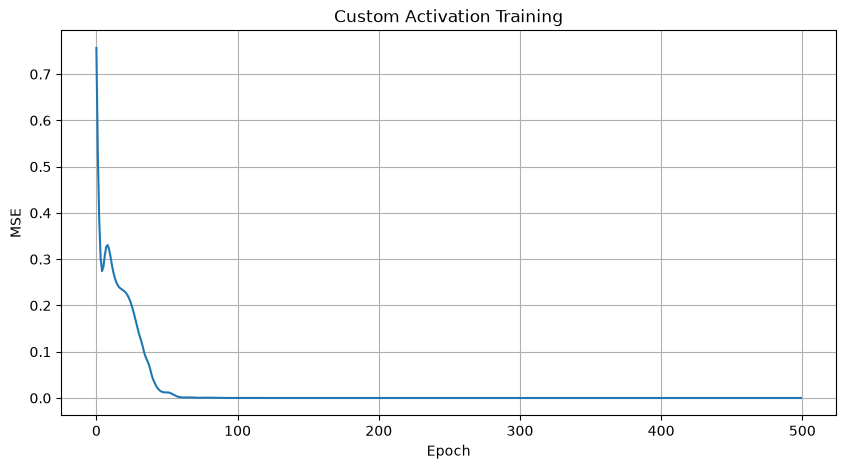

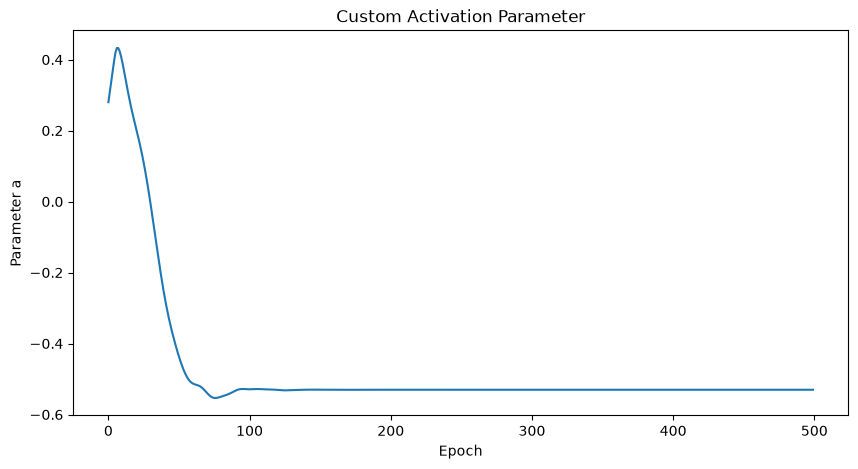

In [5]:
        
print("Эпоха достижения MSE < 0.001:", convergence_epoch)

with torch.no_grad():
    final_predictions = model(X)

print("\nИтоговый a:", model[1].a.item())
print("Предсказания:")
print(final_predictions.flatten().numpy().round(3))


plt.figure(figsize=(10, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Custom Activation Training")
plt.grid()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(a_history)
plt.xlabel("Epoch")
plt.ylabel("Parameter a")
plt.title("Custom Activation Parameter")


### График изменения параметра и переход к DoublePReLU

Наблюдаем траекторию обученного коэффициента. Затем вводим второй вариант активации с двумя независимыми наклонами - на положительной и отрицательной ветвях.

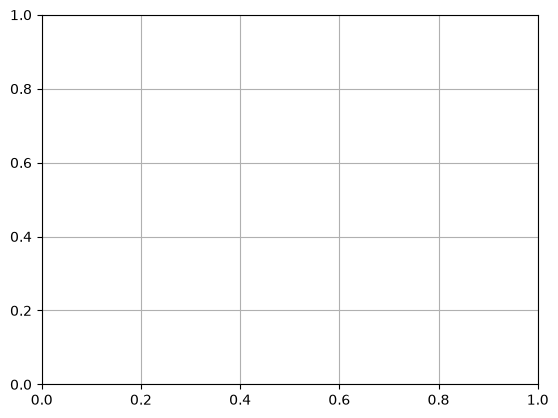

In [6]:
plt.grid()
plt.show()


import torch
from torch import nn
import matplotlib.pyplot as plt


# Собственная функция с двумя параметрами
class DoublePReLU(nn.Module):

    def __init__(self):
        super().__init__()

        self.a = nn.Parameter(torch.tensor(-0.5))
        self.b = nn.Parameter(torch.tensor(1.5))

    def forward(self, x):
        return torch.where(
            x >= 0,
            self.b * x,
            self.a * x
        )


### Повторно подготавливаем данные для сравнения активаций

Перед сравнением DoublePReLU фиксируем входы XOR и список архитектур. Это отдельный эксперимент: результаты предыдущего обучения сюда не передаются.

In [7]:


# Данные XOR
X = torch.tensor([
    [0., 0.],
    [0., 1.],
    [1., 0.],
    [1., 1.]
])

y = torch.tensor([
    [0.],
    [1.],
    [1.],
    [0.]
])


activations = {
    "ReLU": nn.ReLU,
    "PReLU": nn.PReLU,
    "DoublePReLU": DoublePReLU
}

results = {}


### Обучаем ReLU, PReLU и DoublePReLU

Создаём новую модель для каждого варианта и записываем количество эпох до порога. Два коэффициента DoublePReLU дают больше гибкости, но сами по себе не гарантируют лучшего результата.

In [8]:

for name, activation in activations.items():

    torch.manual_seed(42)

    model = nn.Sequential(
        nn.Linear(2, 8),
        activation(),
        nn.Linear(8, 1)
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.03
    )

    loss_fn = nn.MSELoss()

    history = []
    a_history = []
    b_history = []

    convergence_epoch = None
    target_mse = 0.001

    for epoch in range(500):

        optimizer.zero_grad()

        predictions = model(X)
        loss = loss_fn(predictions, y)

        loss.backward()
        if name == "DoublePReLU" and (epoch + 1) % 10 == 0:
              print(
        f"Epoch {epoch + 1:3d} | "
        f"grad_a = {model[1].a.grad.item():+.6f} | "
        f"grad_b = {model[1].b.grad.item():+.6f}"
              )
        optimizer.step()

        with torch.no_grad():
            current_loss = loss_fn(model(X), y).item()

        history.append(current_loss)

        if name == "DoublePReLU":
            a_history.append(model[1].a.item())
            b_history.append(model[1].b.item())

        if (
            current_loss < target_mse
            and convergence_epoch is None
        ):
            convergence_epoch = epoch + 1

    with torch.no_grad():
        final_predictions = model(X)
        final_mse = loss_fn(
            final_predictions, y
        ).item()

    results[name] = {
        "history": history,
        "epoch": convergence_epoch,
        "mse": final_mse
    }

    print(f"\n=== {name} ===")
    print("Эпоха сходимости:", convergence_epoch)
    print("Итоговая MSE:", final_mse)
    print(
        "Предсказания:",
        final_predictions.flatten().numpy().round(3)
    )

    if name == "DoublePReLU":
        print("Обученный a:", model[1].a.item())
        print("Обученный b:", model[1].b.item())



=== ReLU ===
Эпоха сходимости: 75
Итоговая MSE: 5.551115123125783e-17
Предсказания: [-0.  1.  1.  0.]

=== PReLU ===
Эпоха сходимости: 69
Итоговая MSE: 0.0
Предсказания: [0. 1. 1. 0.]
Epoch  10 | grad_a = +0.022329 | grad_b = +0.167643
Epoch  20 | grad_a = +0.029893 | grad_b = +0.023411
Epoch  30 | grad_a = +0.050425 | grad_b = -0.049680
Epoch  40 | grad_a = -0.030063 | grad_b = -0.001840
Epoch  50 | grad_a = +0.014081 | grad_b = -0.000716
Epoch  60 | grad_a = -0.002969 | grad_b = +0.006438
Epoch  70 | grad_a = +0.002821 | grad_b = +0.000896
Epoch  80 | grad_a = -0.002892 | grad_b = -0.000118
Epoch  90 | grad_a = +0.001272 | grad_b = -0.002263
Epoch 100 | grad_a = -0.000842 | grad_b = -0.000212
Epoch 110 | grad_a = +0.000311 | grad_b = +0.000423
Epoch 120 | grad_a = -0.000146 | grad_b = +0.000211
Epoch 130 | grad_a = +0.000260 | grad_b = -0.000057
Epoch 140 | grad_a = -0.000096 | grad_b = +0.000038
Epoch 150 | grad_a = -0.000076 | grad_b = -0.000018
Epoch 160 | grad_a = +0.000071 | gr

### Сравниваем кривые ошибок

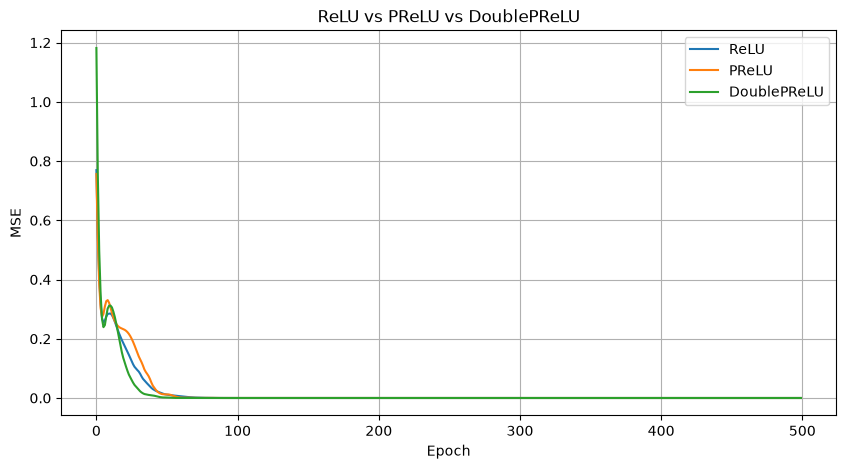

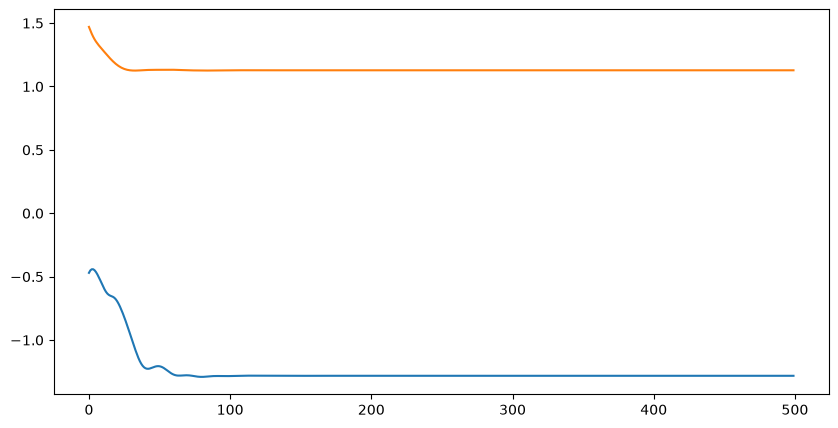

In [9]:


# График сравнения обучения
plt.figure(figsize=(10, 5))

for name, result in results.items():
    plt.plot(
        result["history"],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("ReLU vs PReLU vs DoublePReLU")
plt.legend()
plt.grid()
plt.show()


# График обучения коэффициентов
plt.figure(figsize=(10, 5))

plt.plot(a_history, label="Parameter a")
plt.plot(b_history, label="Parameter b")


C:\Users\Dad\AppData\Local\Temp\ipykernel_25500\1139858953.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


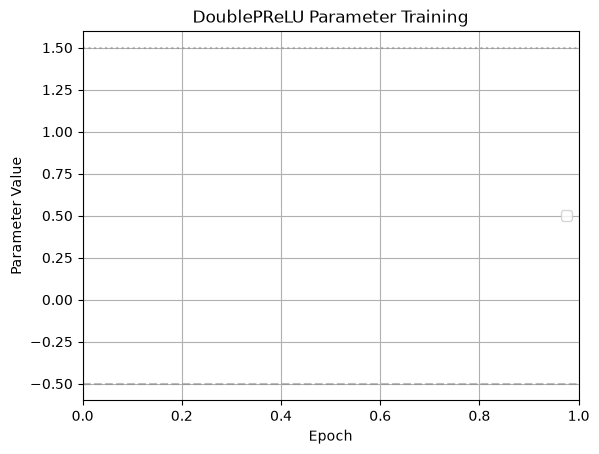

In [10]:

plt.axhline(
    -0.5,
    linestyle="--",
    color="gray",
    alpha=0.5
)

plt.axhline(
    1.5,
    linestyle=":",
    color="gray",
    alpha=0.5
)

plt.xlabel("Epoch")
plt.ylabel("Parameter Value")
plt.title("DoublePReLU Parameter Training")
plt.legend()
plt.grid()
plt.show()


## Выводы

Параметры собственной активации обучаются вместе с весами сети. DoublePReLU меняет наклоны обеих ветвей; их значения и число эпох сравниваем по результатам обучения XOR.


## Полный код


In [ ]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)

import torch
from torch import nn
import matplotlib.pyplot as plt


# Собственная функция активации
class MyActivation(nn.Module):

    def __init__(self, init_a=0.25):
        super().__init__()

        self.a = nn.Parameter(
            torch.tensor(float(init_a))
        )

    def forward(self, x):
        return torch.where(
            x >= 0,
            x,
            self.a * x
        )


# Данные XOR
X = torch.tensor([
    [0., 0.],
    [0., 1.],
    [1., 0.],
    [1., 1.]
])

y = torch.tensor([
    [0.],
    [1.],
    [1.],
    [0.]
])


torch.manual_seed(42)

model = nn.Sequential(
    nn.Linear(2, 8),
    MyActivation(init_a=0.25),
    nn.Linear(8, 1)
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.03
)

loss_fn = nn.MSELoss()

loss_history = []
a_history = []

print("Начальный a:", model[1].a.item())

target_mse = 0.001
convergence_epoch = None

for epoch in range(500):

    optimizer.zero_grad()

    predictions = model(X)
    loss = loss_fn(predictions, y)

    loss.backward()
    optimizer.step()

    with torch.no_grad():
        current_loss = loss_fn(model(X), y).item()

    if current_loss < target_mse and convergence_epoch is None:
        convergence_epoch = epoch + 1

    loss_history.append(current_loss)
    a_history.append(model[1].a.item())

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"MSE: {current_loss:.6f} | "
            f"a: {model[1].a.item():.4f}"
        )
        
print("Эпоха достижения MSE < 0.001:", convergence_epoch)

with torch.no_grad():
    final_predictions = model(X)

print("\nИтоговый a:", model[1].a.item())
print("Предсказания:")
print(final_predictions.flatten().numpy().round(3))


plt.figure(figsize=(10, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Custom Activation Training")
plt.grid()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(a_history)
plt.xlabel("Epoch")
plt.ylabel("Parameter a")
plt.title("Custom Activation Parameter")
plt.grid()
plt.show()


import torch
from torch import nn
import matplotlib.pyplot as plt


# Собственная функция с двумя параметрами
class DoublePReLU(nn.Module):

    def __init__(self):
        super().__init__()

        self.a = nn.Parameter(torch.tensor(-0.5))
        self.b = nn.Parameter(torch.tensor(1.5))

    def forward(self, x):
        return torch.where(
            x >= 0,
            self.b * x,
            self.a * x
        )


# Данные XOR
X = torch.tensor([
    [0., 0.],
    [0., 1.],
    [1., 0.],
    [1., 1.]
])

y = torch.tensor([
    [0.],
    [1.],
    [1.],
    [0.]
])


activations = {
    "ReLU": nn.ReLU,
    "PReLU": nn.PReLU,
    "DoublePReLU": DoublePReLU
}

results = {}

for name, activation in activations.items():

    torch.manual_seed(42)

    model = nn.Sequential(
        nn.Linear(2, 8),
        activation(),
        nn.Linear(8, 1)
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.03
    )

    loss_fn = nn.MSELoss()

    history = []
    a_history = []
    b_history = []

    convergence_epoch = None
    target_mse = 0.001

    for epoch in range(500):

        optimizer.zero_grad()

        predictions = model(X)
        loss = loss_fn(predictions, y)

        loss.backward()
        if name == "DoublePReLU" and (epoch + 1) % 10 == 0:
              print(
        f"Epoch {epoch + 1:3d} | "
        f"grad_a = {model[1].a.grad.item():+.6f} | "
        f"grad_b = {model[1].b.grad.item():+.6f}"
              )
        optimizer.step()

        with torch.no_grad():
            current_loss = loss_fn(model(X), y).item()

        history.append(current_loss)

        if name == "DoublePReLU":
            a_history.append(model[1].a.item())
            b_history.append(model[1].b.item())

        if (
            current_loss < target_mse
            and convergence_epoch is None
        ):
            convergence_epoch = epoch + 1

    with torch.no_grad():
        final_predictions = model(X)
        final_mse = loss_fn(
            final_predictions, y
        ).item()

    results[name] = {
        "history": history,
        "epoch": convergence_epoch,
        "mse": final_mse
    }

    print(f"\n=== {name} ===")
    print("Эпоха сходимости:", convergence_epoch)
    print("Итоговая MSE:", final_mse)
    print(
        "Предсказания:",
        final_predictions.flatten().numpy().round(3)
    )

    if name == "DoublePReLU":
        print("Обученный a:", model[1].a.item())
        print("Обученный b:", model[1].b.item())


# График сравнения обучения
plt.figure(figsize=(10, 5))

for name, result in results.items():
    plt.plot(
        result["history"],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("ReLU vs PReLU vs DoublePReLU")
plt.legend()
plt.grid()
plt.show()


# График обучения коэффициентов
plt.figure(figsize=(10, 5))

plt.plot(a_history, label="Parameter a")
plt.plot(b_history, label="Parameter b")

plt.axhline(
    -0.5,
    linestyle="--",
    color="gray",
    alpha=0.5
)

plt.axhline(
    1.5,
    linestyle=":",
    color="gray",
    alpha=0.5
)

plt.xlabel("Epoch")
plt.ylabel("Parameter Value")
plt.title("DoublePReLU Parameter Training")
plt.legend()
plt.grid()
plt.show()
